# LSST deep field: survey logs to lightcurve fit

This notebook runs the complete chain for LSST, in one deep drilling field (COSMOS), for **Type Ia supernovae (SNe Ia) during the first year** of
the survey, as in *Survey logs to lightcurve fit*:

1. Load the LSST survey from the observing strategy simulation (OpSim **baseline v5.1**).
2. Draw the SNe Ia with the volumetric rate of Frohmaier et al. (2019).
3. Build the dataset of simulated lightcurves.
4. Keep the well-sampled lightcurves and fit them with SALT2.

Each step is timed, and the result is checked against expectations: number of SNe Ia drawn, and fitted versus true
parameters.

:::{note}
- This needs the OpSim database `baseline_v5.1.0_10yrs.db` (SQLite, ~700 MB), from the
  [Rubin simulation archive](https://s3df.slac.stanford.edu/data/rubin/sim-data/). Set `OPSIM_FILEPATH` below.
- The fits need `iminuit` (sncosmo) and `saltjax` (`pip install skysurvey[saltjax]`).
:::

In [1]:
import time
import warnings

import numpy as np
import pandas
import matplotlib.pyplot as plt
from shapely import geometry

import skysurvey
from skysurvey.target.snia import frohmaier_rate
from skysurvey.target.rates import get_ntargets
from skysurvey.tools.projection import skyarea_to_skysurface
from skysurvey.lcfit import fit_salt, fit_salt_jax

OPSIM_FILEPATH = "baseline_v5.1.0_10yrs.db" # replace with the path to your OpSim file
timings = {} # step -> duration in seconds

## 1. Load the deep field visits

OpSim (v5.1) tags each visit with the reason it was taken (`observation_reason`): the visits of the deep drilling
sequences of the COSMOS field are `ddf_cosmos` (the other deep fields are `ddf_ecdfs`, `ddf_elaiss1`, `ddf_xmm_lss`,
`ddf_edfs_a` and `ddf_edfs_b`). We load only these visits, during the first year (`night < 365`), with the `sql_where`
argument of {meth}`skysurvey.LSST.from_opsim`, which then projects the camera on the sky for each of them, with its
boresight and its rotation (`rotSkyPos`). By default (`per_ccd=True`), a position must fall on one of the 189 CCDs to
be observed: the gaps between CCDs are not.

Each visit comes with its `skynoise`, from the OpSim 5-sigma depth (sky, seeing, airmass, read noise), and its `gain`
(electrons per flux unit), from the instrumental zero points of [SMTN-002](https://smtn-002.lsst.io/) and the exposure
time.

In [2]:
ra_ddf, dec_ddf = 150.1, 2.18 # COSMOS deep drilling field [deg]

start = time.perf_counter()
survey = skysurvey.LSST.from_opsim(OPSIM_FILEPATH, sql_where="night < 365 AND observation_reason = 'ddf_cosmos'")
timings["1. load deep field visits (year 1)"] = time.perf_counter() - start

print(f"{len(survey.data):,} visits loaded in {timings['1. load deep field visits (year 1)']:.1f} s")
survey.data.head()

559 visits loaded in 0.2 s


,mjd,band,skynoise,gain,zp,fieldid,ra,dec,rotskypos
0,61024.25000,lsstu,103.223549,1.540932,30,16964,149.886017,1.918315,169.010681
1,61024.25000,lsstu,107.375328,1.540932,30,16965,150.480179,2.338438,168.496399
2,61024.25000,lsstu,105.824501,1.540932,30,16966,150.198166,2.244966,168.323669
3,61025.21875,lsstu,170.059357,1.540932,30,17569,150.319641,2.438361,94.874588
4,61025.21875,lsstu,160.247406,1.540932,30,17570,150.092682,2.540165,94.399361


Here is the number of deep drilling visits around COSMOS during the first year: the camera rotation changes from
visit to visit, so the coverage is round.

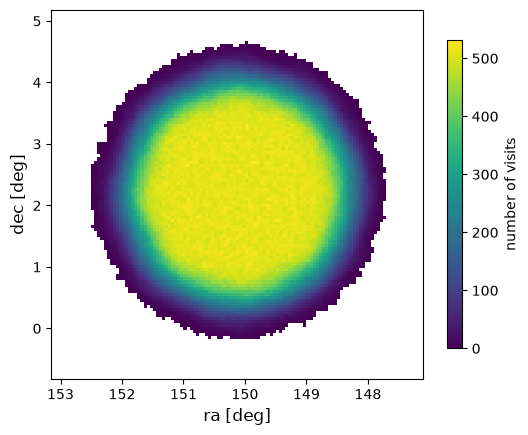

In [3]:
fig = survey.show_nvisits_map(ra_ddf, dec_ddf, size=6, step=0.05)

These are only the deep drilling visits: the wide survey also observes this area. To quantify it, we load all the
visits of the first year pointed within 4.5 deg of the field (enough for any position within 2.5 deg of the center,
given the camera half-width of 1.76 deg) and count those covering the field center:

In [4]:
box = (f"fieldRA BETWEEN {ra_ddf - 4.5} AND {ra_ddf + 4.5} "
       f"AND fieldDec BETWEEN {dec_ddf - 4.5} AND {dec_ddf + 4.5}")
survey_all = skysurvey.LSST.from_opsim(OPSIM_FILEPATH, sql_where=f"night < 365 AND {box}")

center = pandas.DataFrame({"ra": [ra_ddf], "dec": [dec_ddf]})
nvisits_ddf, nvisits_all = len(survey.radec_to_fieldid(center)), len(survey_all.radec_to_fieldid(center))
print(f"visits covering the field center: {nvisits_ddf} deep drilling visits out of {nvisits_all} "
      f"({1 - nvisits_ddf / nvisits_all:.0%} from the wide survey)")

visits covering the field center: 510 deep drilling visits out of 585 (13% from the wide survey)


To include the wide survey visits, use `survey_all` (all visits pointed near the field) instead of `survey` in the
following. Here we keep the deep drilling visits only.

## 2. Draw the SNe Ia

The SN Ia volumetric rate evolves with redshift as $r(z) = r_0 (1+z)^\alpha$, with
$r_0 = 2.27 \times 10^4\,\mathrm{Gpc^{-3}\,yr^{-1}}$ (for $H_0 = 70$) and $\alpha = 1.70$, as fitted by
[Frohmaier et al. (2019)](https://arxiv.org/abs/1903.08580) for $z < 1$
({func}`skysurvey.target.snia.frohmaier_rate`). We draw all the SNe Ia exploding up to $z = 1$ (the validity range of the rate) within 2.5 deg of the field center (the camera half-width,
1.76 deg, plus the dithering of the pointings), from 50 days before the
first visit to 20 days after the last one (SNe Ia exploding just before the survey are seen declining).

In [5]:
zmax = 1.0
skyarea = geometry.Point(ra_ddf, dec_ddf).buffer(2.5) # [deg]
skyfraction = skyarea_to_skysurface(skyarea)
tstart, tstop = survey.data["mjd"].min() - 50, survey.data["mjd"].max() + 20

start = time.perf_counter()
snia = skysurvey.SNeIa.from_draw(tstart=tstart, tstop=tstop, zmax=zmax, rate=frohmaier_rate, skyarea=skyarea)
timings["2. draw targets"] = time.perf_counter() - start

In [6]:
# expected number: rate x comoving volume / (1+z) x time x sky fraction, independently of the draw
duration = (tstop - tstart) / 365.25 # [yr]
expected = get_ntargets(zmax, rate=frohmaier_rate, cosmology=snia.cosmology, astype=float) * duration * skyfraction
print(f"{len(snia.data):,} SNe Ia drawn in {timings['2. draw targets']:.1f} s (expected: {expected:,.0f})")
snia.data.head()

1,707 SNe Ia drawn in 0.3 s (expected: 1,708)


,z,x1,c,t0,ra,dec,magabs,magobs,template
0,0.81995,-1.225,0.797,61107.582031,150.869980,4.385865,-16.824890,26.804846,salt2
1,0.48545,-1.340,0.142,61171.144531,151.325546,2.000415,-18.678171,23.571817,salt2
2,0.71185,0.280,-0.038,61236.671875,149.979401,1.851778,-19.433168,23.820959,salt2
3,0.97815,-0.395,0.173,61096.796875,150.086441,4.624155,-18.854006,25.246662,salt2
4,0.95915,-1.825,0.302,61097.199219,148.016632,0.948036,-18.056780,25.991440,salt2


## 3. Build the dataset

{meth}`skysurvey.DataSet.from_targets_and_survey` finds the visits covering each SN Ia (on a CCD), and simulates the
flux of every visit between $-50$ and $+200$ rest-frame days around maximum, with its error and a seeded noise
realisation.

In [7]:
start = time.perf_counter()
dset = skysurvey.DataSet.from_targets_and_survey(snia, survey, seed=1234)
timings["3. build dataset"] = time.perf_counter() - start

print(f"{len(dset.data):,} observations of {len(dset.obs_index):,} SNe Ia simulated in {timings['3. build dataset']:.1f} s")
dset.data.head()

305,862 observations of 1,541 SNe Ia simulated in 2.5 s


mjd   band    skynoise      gain  zp  fieldid  \
index index_obs                                                           
0     282        61121.109375  lssti   67.274132  5.560595  30    61434   
      348        61143.058594  lsstg   27.992767  7.605386  30    75704   
      424        61162.984375  lsstg   68.793411  7.605386  30    91032   
      451        61168.097656  lsstz  150.181320  3.882587  30    93532   
1     192        61098.035156  lssty  518.614990  1.603693  30    47533   

                       flux     fluxerr  
index index_obs                          
0     282        -89.809783   67.298353  
      348          1.802817   27.992787  
      424         50.974529   68.793415  
      451         27.205662  150.184997  
1     192        447.950523  518.614982

## 4. Fit the lightcurves

### Quality cut

We keep the SNe Ia with **at least 5 detections** (flux/fluxerr $\geq 5$) between $-10$ and $+40$ rest-frame days, the
phase range used by the fits, taken on **at least 3 different nights**: LSST often takes several visits of the same
field in a night, and detections from a single night do not constrain the shape of the lightcurve.

394 of the 1,707 SNe Ia pass the cut (0.0 s)


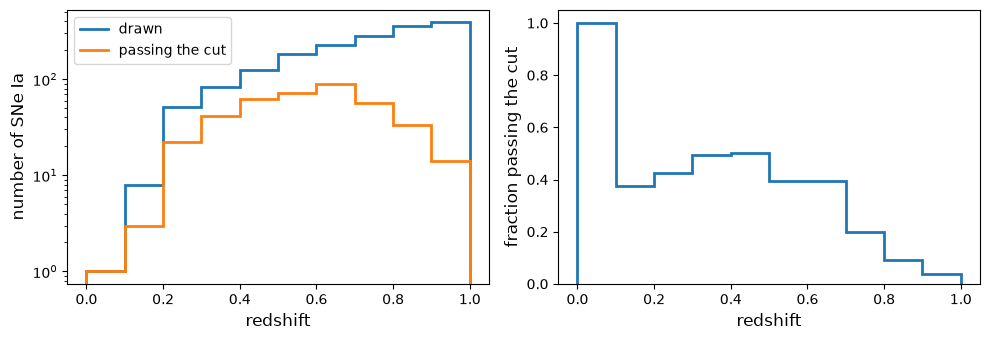

In [8]:
phase_range = [-10, 40] # rest-frame days, used both for the cut and the fits

start = time.perf_counter()
detections = dset.get_data(phase_range=phase_range, detection=True)
ndetection = detections.groupby(level=0).size()
nnights = detections.assign(night=np.floor(detections["mjd"])).groupby(level=0)["night"].nunique()
good = ndetection[(ndetection >= 5) & (nnights >= 3)].index
timings["4a. quality cut"] = time.perf_counter() - start

print(f"{len(good):,} of the {len(snia.data):,} SNe Ia pass the cut ({timings['4a. quality cut']:.1f} s)")

fig, (axn, axf) = plt.subplots(1, 2, figsize=(10, 3.5))
zbins = np.linspace(0, zmax, 11)
ndrawn = np.histogram(snia.data["z"], zbins)[0]
npassing = np.histogram(snia.data.loc[good, "z"], zbins)[0]
axn.stairs(ndrawn, zbins, lw=2, label="drawn")
axn.stairs(npassing, zbins, lw=2, label="passing the cut")
axn.set_yscale("log")
axn.set_ylabel("number of SNe Ia", fontsize="large")
axn.legend()
axf.stairs(npassing / np.maximum(ndrawn, 1), zbins, lw=2)
axf.set_ylabel("fraction passing the cut", fontsize="large")
axf.set_ylim(0, 1.05)
for ax in [axn, axf]:
    ax.set_xlabel("redshift", fontsize="large")
fig.tight_layout()

At low redshift, the fraction passing the cut is limited by the observing season (the few SNe Ia there make it noisy):
SNe Ia peaking up to 50 days before the first visit, or between visits separated by a long gap, are not well sampled.
Among the SNe Ia peaking while the field is observed, most pass the cut:

In [9]:
# observing season: first and last visit covering the field center
fieldids = survey.radec_to_fieldid(pandas.DataFrame({"ra": [ra_ddf], "dec": [dec_ddf]}))
mjd_field = survey.data.set_index("fieldid").loc[fieldids["fieldid"], "mjd"]
in_season = snia.data["t0"].between(mjd_field.min(), mjd_field.max())
print(f"{len(mjd_field)} visits on the field center, during {mjd_field.max() - mjd_field.min():.0f} days "
      f"(SNe Ia drawn over {tstop - tstart:.0f} days)")
for zlim in [0.5, zmax]:
    in_season_ = snia.data.index[in_season & (snia.data["z"] < zlim)]
    print(f"z < {zlim}: {np.isin(in_season_, good).mean():.0%} of the SNe Ia peaking in the season pass the cut")

510 visits on the field center, during 200 days (SNe Ia drawn over 270 days)
z < 0.5: 63% of the SNe Ia peaking in the season pass the cut
z < 1.0: 31% of the SNe Ia peaking in the season pass the cut


A typical lightcurve passing the cut (the SN Ia with the median number of detections); the lines show the true model.

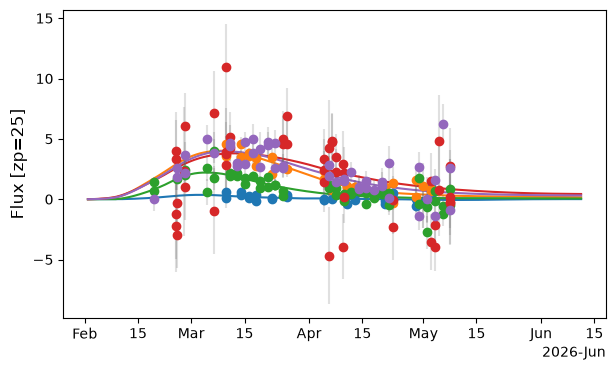

In [10]:
ndetection_good = ndetection.loc[good]
typical = (ndetection_good - ndetection_good.median()).abs().idxmin()
fig = dset.show_target_lightcurve(index=typical, phase_window=[-20, 60])

### Option 1: sncosmo, one target at a time

{func}`skysurvey.lcfit.fit_salt` fits each lightcurve with {func}`sncosmo.fit_lc` (redshift fixed, SALT2 model
covariance included). It starts from the **true** parameters, slightly scattered, within `bounds` that we widen so
they do not truncate the fit.

In [11]:
# the simulated fluxes are in the AB system; sncosmo needs it as an explicit column.
dset.data["zpsys"] = "ab"

start = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # sncosmo/iminuit convergence chatter
    fits_sncosmo = fit_salt(dset, indexes=good, phase_range=phase_range,
                            bounds={"t0": 10, "x1": 4, "c": 0.6}).astype(float)
timings["4b. fit (sncosmo)"] = time.perf_counter() - start

print(f"{len(fits_sncosmo):,} fits in {timings['4b. fit (sncosmo)']:.0f} s "
      f"({timings['4b. fit (sncosmo)'] / len(good) * 1e3:.0f} ms per SN)")

394 fits in 78 s (197 ms per SN)


### Option 2: saltjax, all targets at once

{func}`skysurvey.lcfit.fit_salt_jax` fits all lightcurves together with [saltjax](https://github.com/MickaelRigault/saltjax)
(same SALT2 model, chi2 and model covariance), starting from a guess computed from the data. The first call includes
the JAX compilation.

In [12]:
start = time.perf_counter()
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # summary warnings, see the converged and valid columns
    fits_jax = fit_salt_jax(dset, indexes=good, phase_range=phase_range)
timings["4c. fit (saltjax)"] = time.perf_counter() - start

print(f"{len(fits_jax):,} fits in {timings['4c. fit (saltjax)']:.0f} s "
      f"({timings['4c. fit (saltjax)'] / len(good) * 1e3:.1f} ms per SN), {fits_jax['converged'].mean():.1%} converged")
fits_jax[["z", "t0", "x0", "x1", "x1_err", "c", "c_err", "chi2", "ndof", "converged"]].head()

394 fits in 27 s (69.5 ms per SN), 98.5% converged


,z,t0,x0,x1,x1_err,c,c_err,chi2,ndof,converged
1,0.48545,61170.974134,0.000006,-0.589916,0.577853,0.113624,0.039383,120.292304,133.0,True
5,0.62615,61071.050743,0.000007,1.601748,0.529044,0.052993,0.039647,179.133423,162.0,True
6,0.51555,61110.748720,0.000009,-1.307466,0.205986,0.005607,0.030540,197.514034,249.0,True
7,0.34555,61074.534215,0.000017,-0.205183,0.154390,0.065185,0.024009,191.173617,190.0,True
9,0.50905,61081.166855,0.000005,0.268679,0.399596,0.239134,0.042170,206.719570,209.0,True


### Do the fits recover the truth?

Since this is a simulation, we know the true parameters. The **pulls**, (fitted - true) / error, must follow a normal
distribution $\mathcal{N}(0, 1)$ if the fits are unbiased and their errors correct. We quote the robust standard
deviation (1.4826 x the median absolute deviation), insensitive to the few failed fits.

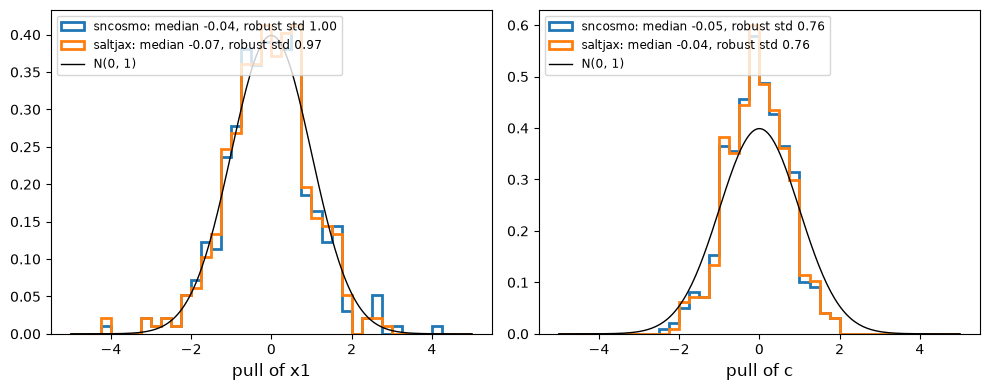

In [13]:
truth = snia.data

def get_pulls(fits, key):
    """(fitted - true) / error of the given parameter."""
    return ((fits[key] - truth.loc[fits.index, key]) / fits[f"{key}_err"]).dropna()

def get_robust_std(values):
    """1.4826 x median absolute deviation (= std for a normal distribution)."""
    return 1.4826 * np.median(np.abs(values - np.median(values)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, ["x1", "c"]):
    for fits_, label_ in [(fits_sncosmo, "sncosmo"), (fits_jax.query("converged"), "saltjax")]:
        pulls = get_pulls(fits_, key)
        ax.hist(pulls, bins=np.linspace(-5, 5, 41), histtype="step", lw=2, density=True,
                label=f"{label_}: median {np.median(pulls):+.2f}, robust std {get_robust_std(pulls):.2f}")
    xx = np.linspace(-5, 5, 200)
    ax.plot(xx, np.exp(-0.5 * xx**2) / np.sqrt(2 * np.pi), color="k", lw=1, label="N(0, 1)")
    ax.set_xlabel(f"pull of {key}", fontsize="large")
    ax.legend(fontsize="small", loc="upper left")
fig.tight_layout()

The pulls are centered on zero: the fits are unbiased. They are narrower than $\mathcal{N}(0, 1)$, the color ones
especially: the fits include the SALT2 model covariance (`modelcov=True`, the standard choice for real data), which adds
the model uncertainty to the errors, while these SNe Ia were simulated with the very same model. Without it, both pulls
follow $\mathcal{N}(0, 1)$:

In [14]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fits_nomodelcov = fit_salt_jax(dset, indexes=good, phase_range=phase_range, modelcov=False).query("converged")

for key in ["x1", "c"]:
    pulls = get_pulls(fits_nomodelcov, key)
    print(f"modelcov=False, {key}: median {np.median(pulls):+.2f}, robust std {get_robust_std(pulls):.2f}")

modelcov=False, x1: median -0.02, robust std 1.03
modelcov=False, c: median -0.05, robust std 1.08


## Timing summary

In [15]:
pandas.Series(timings, name="time [s]").round(1).to_frame()

,time [s]
1. load deep field visits (year 1),0.2
2. draw targets,0.3
3. build dataset,2.5
4a. quality cut,0.0
4b. fit (sncosmo),77.7
4c. fit (saltjax),27.4


## Assumptions

- **Survey**: OpSim baseline v5.1, first year; one 5-sigma depth per visit for all CCDs; camera rotation convention
  from the Rubin documentation (see {class}`skysurvey.LSST`).
- **SNe Ia**: SALT2 model; default {class}`skysurvey.SNeIa` populations of stretch and color, Tripp standardisation;
  no Milky Way extinction nor host galaxy contamination.
- **Volume**: SNe Ia up to $z = 1$, the validity range of the rate; a few SNe Ia beyond could be detected in the
  deep field.